# Generating Data
> We constrain the balls to a 2D box and have them interact with the walls

We will feed velocities $\langle v_x, v_y \rangle$ into the model and an intitial start position $\langle x_0, y_0 \rangle$ and have the model guess correct position $\langle x, y \rangle$. To do this we must generate several fields and simulate trajectories and save the trajectories as respective tensors. For each run, data should be stored as 


```
trial : {
    pos : [list of (x, y) at each t]
    vel : [list of (v_x, v_y) at each t]
    init : (x_0, y_0)
}
```

In [1]:
LEFT = -1
RIGHT = 1

TOP = 1
BOT = -1

v_min = -0.1
v_max = 0.1

N=10_000
T=150


In [2]:
import numpy as np

rng = np.random.default_rng(seed=42)

x_0 = rng.uniform(LEFT, RIGHT, size=N)
y_0 = rng.uniform(BOT, TOP, size=N)
vx = rng.uniform(v_min, v_max, size=N)     # current velocity (changes at bounces)
vy = rng.uniform(v_min, v_max, size=N)

def reflect(p, v, lo, hi):
    over = p > hi;  p[over] = 2*hi - p[over];  v[over] *= -1
    under = p < lo; p[under] = 2*lo - p[under]; v[under] *= -1
    return p, v

x_t = np.zeros((N, T)); y_t = np.zeros((N, T))
x_t[:, 0], y_t[:, 0] = x_0, y_0

for t in range(1, T):
    x, vx = reflect(x_t[:, t-1] + vx, vx, LEFT, RIGHT)
    y, vy = reflect(y_t[:, t-1] + vy, vy, BOT, TOP)
    x_t[:, t], y_t[:, t] = x, y

# Velocity input = actual displacement each step, so x_t = x_0 + cumsum(v) exactly.
v_xt = np.zeros((N, T)); v_yt = np.zeros((N, T))
v_xt[:, 1:] = np.diff(x_t, axis=1)
v_yt[:, 1:] = np.diff(y_t, axis=1)

In [3]:
np.savez_compressed("particles.npz", x_0=x_0, y_0=y_0, x_t=x_t, y_t=y_t, v_xt=v_xt, v_yt=v_yt)

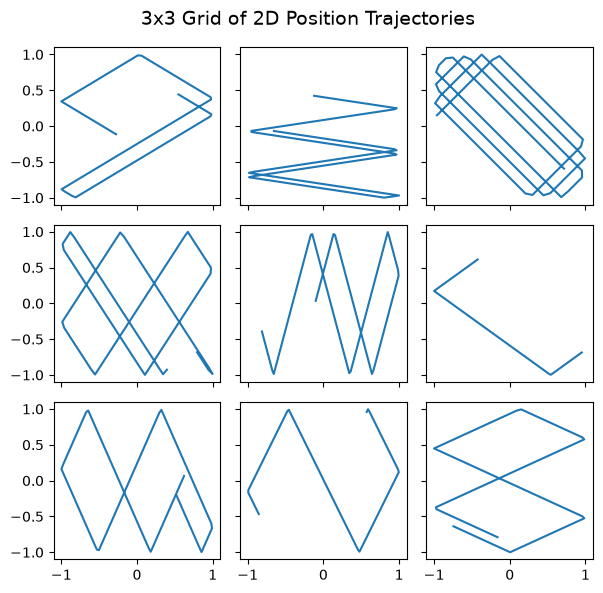

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(6, 6), sharex=True, sharey=True)

for idx, ax in enumerate(axes.flat):
    ax.plot(x_t[idx], y_t[idx])

fig.suptitle("3x3 Grid of 2D Position Trajectories", fontsize=14)
plt.tight_layout()
plt.show()